# 16 — Toronto final synthesis, visual workflow, and Quarto export

## Purpose

This is the final synthesis notebook for the Toronto heat-conditioned accessibility proof-of-concept.

It has four jobs:

1. **clean the previous Quarto asset handoff** so the final export starts from a known state;
2. **reconstruct a visual story of the workflow**, from study area to thermal network to accessibility and Bike Share response;
3. **export polished figures and tables** into `data/toronto/processed/`;
4. **produce a Quarto-ready asset inventory** for the public project page.

### Conceptual chain

**Urban form + meteorology → UTCI → thermal network impedance → heat-conditioned accessibility → observed mobility response**

### Cleanup behavior

At the beginning, this notebook removes only:

`data/toronto/processed/quarto_assets/`

It does **not** remove anything from `raw/`, `interim/`, `outputs/`, or other processed outputs.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [25]:
from pathlib import Path
import shutil
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import osmnx as ox
import pandas as pd
import rasterio
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
RAW = TORONTO_DATA / "raw"
INTERIM = TORONTO_DATA / "interim"
PROCESSED = TORONTO_DATA / "processed"
OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

print("Project root:", PROJECT_ROOT)
print("Toronto data:", TORONTO_DATA)
print("Toronto outputs:", OUTPUTS)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
Toronto data: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto
Toronto outputs: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto


## 2. Clean previous Quarto assets

This is the only destructive step. It removes only the previous draft folder:

`data/toronto/processed/quarto_assets/`

In [26]:
OLD_QUARTO_ASSETS = PROCESSED / "quarto_assets"

if OLD_QUARTO_ASSETS.exists():
    shutil.rmtree(OLD_QUARTO_ASSETS)
    print("Removed previous Quarto assets:")
    print(OLD_QUARTO_ASSETS)
else:
    print("No previous Quarto asset folder found.")

FINAL_FIGURES = PROCESSED / "final_figures"
FINAL_TABLES = PROCESSED / "final_tables"
FINAL_LAYERS = PROCESSED / "final_layers"

QUARTO_ASSETS = PROCESSED / "quarto_assets"
QUARTO_FIGURES = QUARTO_ASSETS / "figures"
QUARTO_TABLES = QUARTO_ASSETS / "tables"
QUARTO_TEXT = QUARTO_ASSETS / "text"

for path in [
    FINAL_FIGURES,
    FINAL_TABLES,
    FINAL_LAYERS,
    QUARTO_FIGURES,
    QUARTO_TABLES,
    QUARTO_TEXT,
]:
    path.mkdir(parents=True, exist_ok=True)

print("\nFresh export folders:")
for path in [
    FINAL_FIGURES,
    FINAL_TABLES,
    FINAL_LAYERS,
    QUARTO_ASSETS,
]:
    print("-", path)

Removed previous Quarto assets:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/quarto_assets

Fresh export folders:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_tables
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_layers
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/quarto_assets


## 3. Figure registry

In [27]:
FIG = {
    "study_area": FINAL_FIGURES / "fig_01_study_area_overview.png",
    "urban_form": FINAL_FIGURES / "fig_02_buildings_and_trees.png",
    "surface_inputs": FINAL_FIGURES / "fig_03_solweig_surface_inputs.png",
    "scenario_selection": FINAL_FIGURES / "fig_04_thermal_scenario_selection.png",
    "utci_anchor": FINAL_FIGURES / "fig_05_anchor_utci_surface.png",
    "thermal_network_utci": FINAL_FIGURES / "fig_06_thermal_network_utci.png",
    "thermal_network_cost": FINAL_FIGURES / "fig_07_thermal_network_cost_ratio.png",
    "origins_transit": FINAL_FIGURES / "fig_08_origins_and_transit_stops.png",
    "access_loss_map": FINAL_FIGURES / "fig_09_accessibility_loss_map.png",
    "bikeshare_response": FINAL_FIGURES / "fig_10_bikeshare_response_distribution.png",
    "access_bike_scatter": FINAL_FIGURES / "fig_11_accessibility_vs_bikeshare.png",
    "scenario_impedance": FINAL_FIGURES / "fig_12_multiscenario_thermal_impedance.png",
    "scenario_access_loss": FINAL_FIGURES / "fig_13_multiscenario_accessibility_loss.png",
    "sample_robustness": FINAL_FIGURES / "fig_14_robustness_50_vs_75.png",
    "lambda_sensitivity": FINAL_FIGURES / "fig_15_lambda_sensitivity.png",
    "workflow_gallery": FINAL_FIGURES / "fig_16_workflow_gallery.png",
}

pd.DataFrame(
    [{"key": k, "path": str(v)} for k, v in FIG.items()]
)

,key,path
0,study_area,/scratch/project_2010417/paper3/heat-condition...
1,urban_form,/scratch/project_2010417/paper3/heat-condition...
2,surface_inputs,/scratch/project_2010417/paper3/heat-condition...
3,scenario_selection,/scratch/project_2010417/paper3/heat-condition...
4,utci_anchor,/scratch/project_2010417/paper3/heat-condition...
5,thermal_network_utci,/scratch/project_2010417/paper3/heat-condition...
6,thermal_network_cost,/scratch/project_2010417/paper3/heat-condition...
7,origins_transit,/scratch/project_2010417/paper3/heat-condition...
8,access_loss_map,/scratch/project_2010417/paper3/heat-condition...
9,bikeshare_response,/scratch/project_2010417/paper3/heat-condition...


## 4. Helper functions

The synthesis should keep running even if an optional upstream figure or layer is missing.

In [28]:
def existing_path(*candidates):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    return None


def first_match(base, patterns):
    base = Path(base)
    matches = []
    for pattern in patterns:
        matches.extend(sorted(base.rglob(pattern)))
    matches = [p for p in matches if p.is_file()]
    return matches[0] if matches else None


def savefig(fig, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


def plot_raster(path, title, output_path):
    path = Path(path)
    if not path.exists():
        print("Missing raster:", path)
        return False

    with rasterio.open(path) as src:
        arr = src.read(1)

    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    im = ax.imshow(arr)
    ax.set_title(title)
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.75)
    plt.tight_layout()
    savefig(fig, output_path)
    plt.show()
    return True


def convert_graph_numeric(G):
    fields = [
        "length",
        "walk_time_s",
        "utci_1500",
        "heat_excess",
        "thermal_cost_s",
        "cost_ratio",
    ]

    for _, _, _, data in G.edges(keys=True, data=True):
        for field in fields:
            if field in data:
                try:
                    data[field] = float(data[field])
                except Exception:
                    pass
    return G


asset_log = []

def log_asset(stage, label, path, status="created"):
    asset_log.append(
        {
            "stage": stage,
            "label": label,
            "path": str(path) if path is not None else None,
            "status": status,
        }
    )

# Part I — Spatial and thermal workflow

## 5. Study area and walking network

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_01_study_area_overview.png


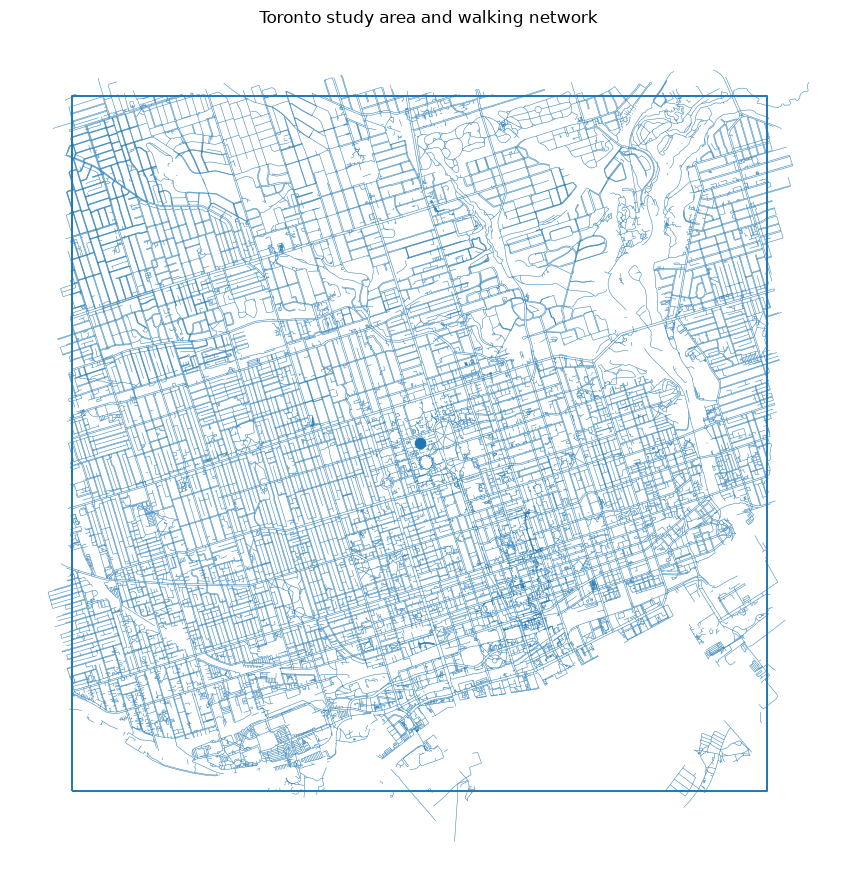

In [29]:
study_area_path = existing_path(
    RAW / "toronto_study_area_8km.gpkg",
)

center_path = existing_path(
    RAW / "toronto_uoft_center.gpkg",
)

walk_graph_path = existing_path(
    RAW / "toronto_walk_8km.graphml",
)

if study_area_path and walk_graph_path:
    study_area = gpd.read_file(study_area_path)
    G_walk = ox.load_graphml(walk_graph_path)

    nodes_walk, edges_walk = ox.graph_to_gdfs(
        G_walk,
        nodes=True,
        edges=True,
        fill_edge_geometry=True,
    )

    study_area_plot = study_area.to_crs(edges_walk.crs)

    fig, ax = plt.subplots(figsize=(9, 9))

    edges_walk.plot(
        ax=ax,
        linewidth=0.35,
        alpha=0.55,
    )

    study_area_plot.boundary.plot(
        ax=ax,
        linewidth=1.4,
    )

    if center_path:
        center = gpd.read_file(center_path).to_crs(edges_walk.crs)
        center.plot(
            ax=ax,
            markersize=55,
        )

    ax.set_title("Toronto study area and walking network")
    ax.set_axis_off()
    plt.tight_layout()
    savefig(fig, FIG["study_area"])
    plt.show()

    log_asset("01", "Study area and walking network", FIG["study_area"])

else:
    print("Study-area or walking-graph input not found.")
    log_asset("01", "Study area and walking network", None, "missing")

## 6. Urban-form inputs: buildings and trees

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_02_buildings_and_trees.png


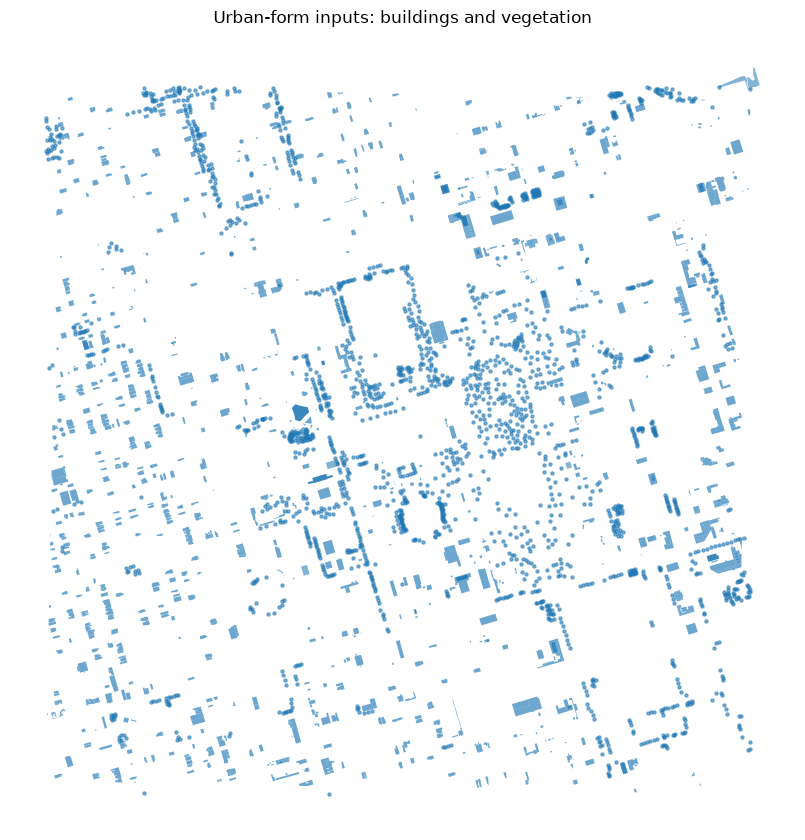

In [30]:
building_path = existing_path(
    INTERIM
    / "voxcity_enriched"
    / "UOFT_PILOT_buildings_toronto_3d_massing.gpkg",
)

tree_path = first_match(
    INTERIM / "voxcity_test",
    [
        "*trees*.gpkg",
        "*tree*.gpkg",
    ],
)

if building_path:
    buildings = gpd.read_file(building_path)

    fig, ax = plt.subplots(figsize=(8.5, 8.5))

    buildings.plot(
        ax=ax,
        linewidth=0.15,
        alpha=0.65,
    )

    if tree_path:
        trees = gpd.read_file(tree_path)

        if trees.crs != buildings.crs:
            trees = trees.to_crs(buildings.crs)

        trees.plot(
            ax=ax,
            markersize=5,
            alpha=0.55,
        )

    ax.set_title("Urban-form inputs: buildings and vegetation")
    ax.set_axis_off()
    plt.tight_layout()
    savefig(fig, FIG["urban_form"])
    plt.show()

    log_asset("02–03", "Buildings and vegetation", FIG["urban_form"])

else:
    print("Enriched building layer not found.")
    log_asset("02–03", "Buildings and vegetation", None, "missing")

## 7. SOLWEIG input surfaces: DEM, DSM, and CDSM

- **DEM** = ground elevation
- **DSM** = terrain + built structures
- **CDSM** = canopy height

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_03_solweig_surface_inputs.png


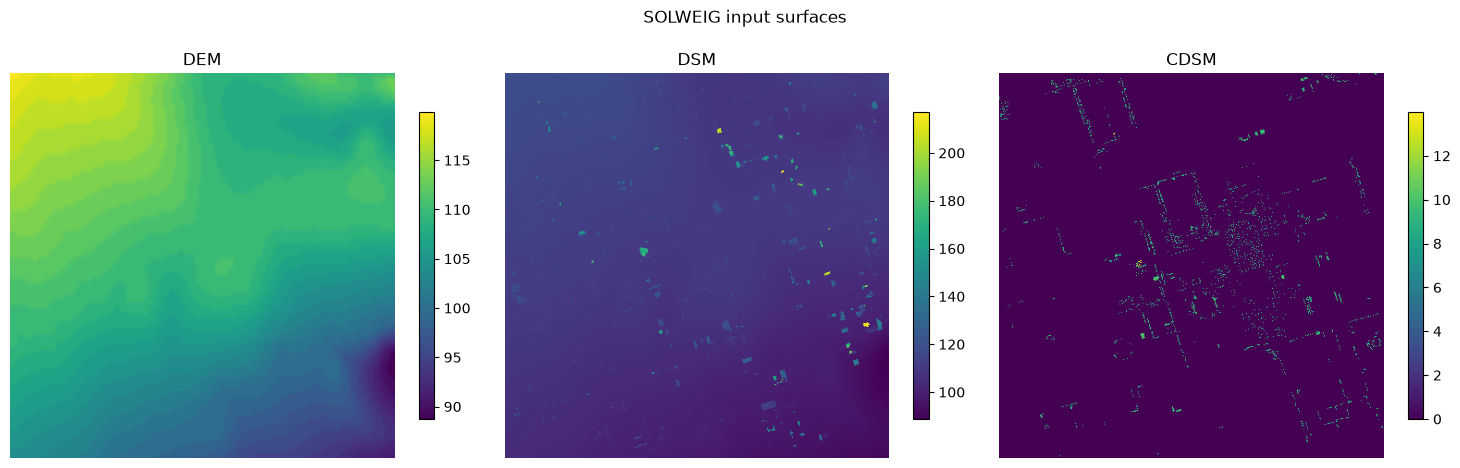

In [31]:
SOLWEIG_INPUT_DIR = INTERIM / "solweig" / "UOFT_PILOT"

dem_path = SOLWEIG_INPUT_DIR / "dem.tif"
dsm_path = SOLWEIG_INPUT_DIR / "dsm.tif"
cdsm_path = SOLWEIG_INPUT_DIR / "cdsm.tif"

surface_paths = [
    ("DEM", dem_path),
    ("DSM", dsm_path),
    ("CDSM", cdsm_path),
]

available = [
    (name, path)
    for name, path in surface_paths
    if path.exists()
]

if available:
    fig, axes = plt.subplots(
        1,
        len(available),
        figsize=(5 * len(available), 5),
    )

    axes = np.atleast_1d(axes)

    for ax, (name, path) in zip(axes, available):
        with rasterio.open(path) as src:
            arr = src.read(1)

        im = ax.imshow(arr)
        ax.set_title(name)
        ax.set_axis_off()
        fig.colorbar(im, ax=ax, shrink=0.7)

    fig.suptitle("SOLWEIG input surfaces")
    plt.tight_layout()
    savefig(fig, FIG["surface_inputs"])
    plt.show()

    log_asset("04", "SOLWEIG input surfaces", FIG["surface_inputs"])

else:
    print("SOLWEIG input rasters not found.")
    log_asset("04", "SOLWEIG input surfaces", None, "missing")

## 8. Thermal scenario selection

A **thermal scenario** is one selected summer meteorological condition evaluated at the common 15:00 analysis time.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_04_thermal_scenario_selection.png


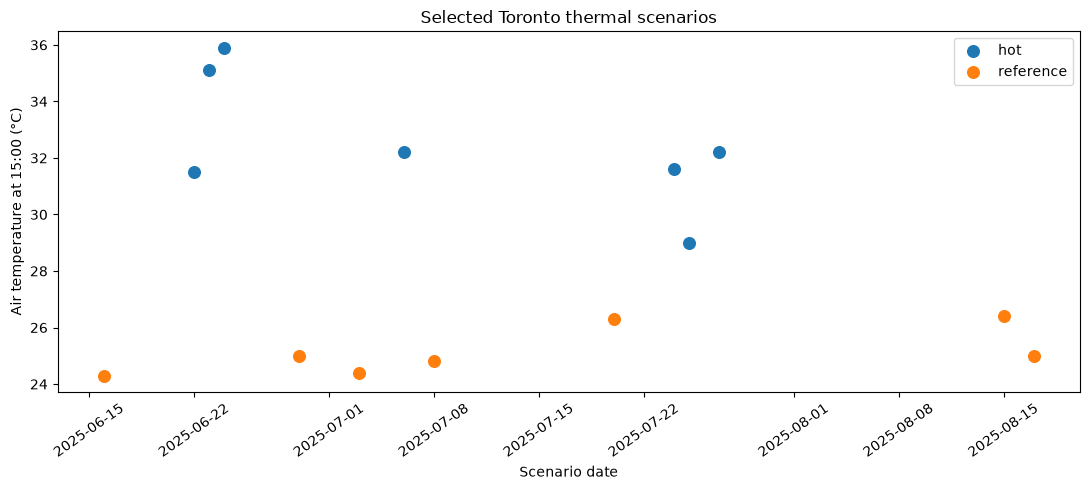

In [32]:
scenario_manifest_path = existing_path(
    OUTPUTS
    / "thermal_scenarios"
    / "toronto_summer2025_solweig_scenario_manifest.csv",
)

if scenario_manifest_path:
    scenario_manifest = pd.read_csv(
        scenario_manifest_path
    )

    scenario_manifest["date"] = pd.to_datetime(
        scenario_manifest["date"]
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    for role in scenario_manifest[
        "scenario_role"
    ].dropna().unique():

        subset = scenario_manifest[
            scenario_manifest[
                "scenario_role"
            ] == role
        ].sort_values("date")

        ax.scatter(
            subset["date"],
            subset["temp_1500_c"],
            s=70,
            label=role,
        )

    ax.set_xlabel("Scenario date")
    ax.set_ylabel("Air temperature at 15:00 (°C)")
    ax.set_title("Selected Toronto thermal scenarios")
    ax.legend()
    plt.xticks(rotation=35)
    plt.tight_layout()
    savefig(fig, FIG["scenario_selection"])
    plt.show()

    scenario_manifest.to_csv(
        FINAL_TABLES / "tbl_02_scenario_manifest.csv",
        index=False,
    )

    log_asset("11", "Thermal scenario selection", FIG["scenario_selection"])

else:
    scenario_manifest = None
    print("Scenario manifest not found.")
    log_asset("11", "Thermal scenario selection", None, "missing")

## 9. Anchor UTCI surface

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_05_anchor_utci_surface.png


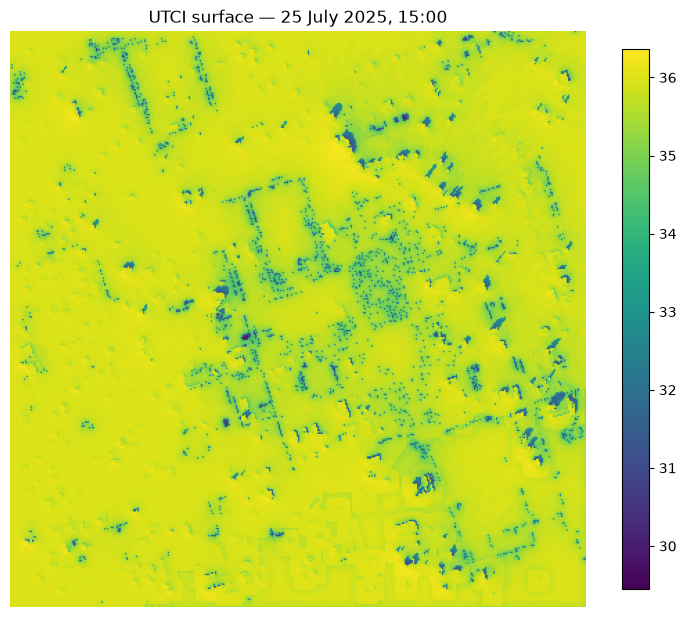

In [33]:
anchor_utci = existing_path(
    OUTPUTS
    / "solweig"
    / "UOFT_PILOT_2025-07-25_1500"
    / "utci_2025-07-25_1500.tif",
)

if anchor_utci:
    if plot_raster(
        anchor_utci,
        "UTCI surface — 25 July 2025, 15:00",
        FIG["utci_anchor"],
    ):
        log_asset(
            "05",
            "Anchor UTCI surface",
            FIG["utci_anchor"],
        )
else:
    print("Anchor UTCI raster not found.")
    log_asset("05", "Anchor UTCI surface", None, "missing")

## 10. Thermal walking network

The thermal-network step is the methodological bridge between the environmental model and accessibility.

Each edge can carry:

- walking time
- edge UTCI
- heat excess
- thermal generalized cost
- thermal-cost ratio

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_06_thermal_network_utci.png


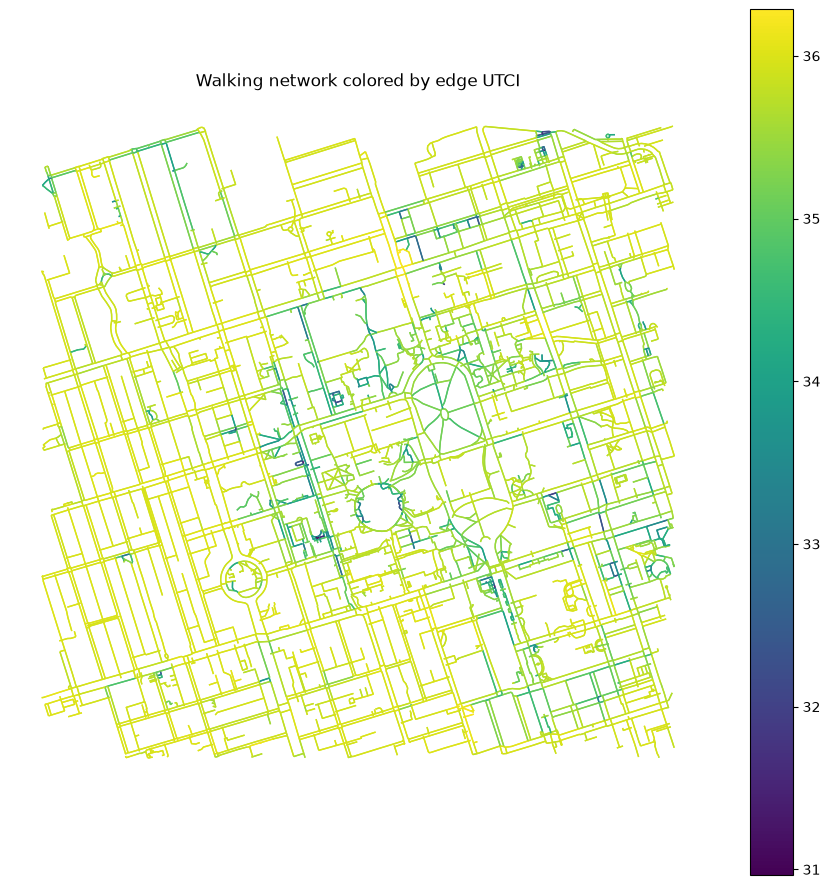

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_07_thermal_network_cost_ratio.png


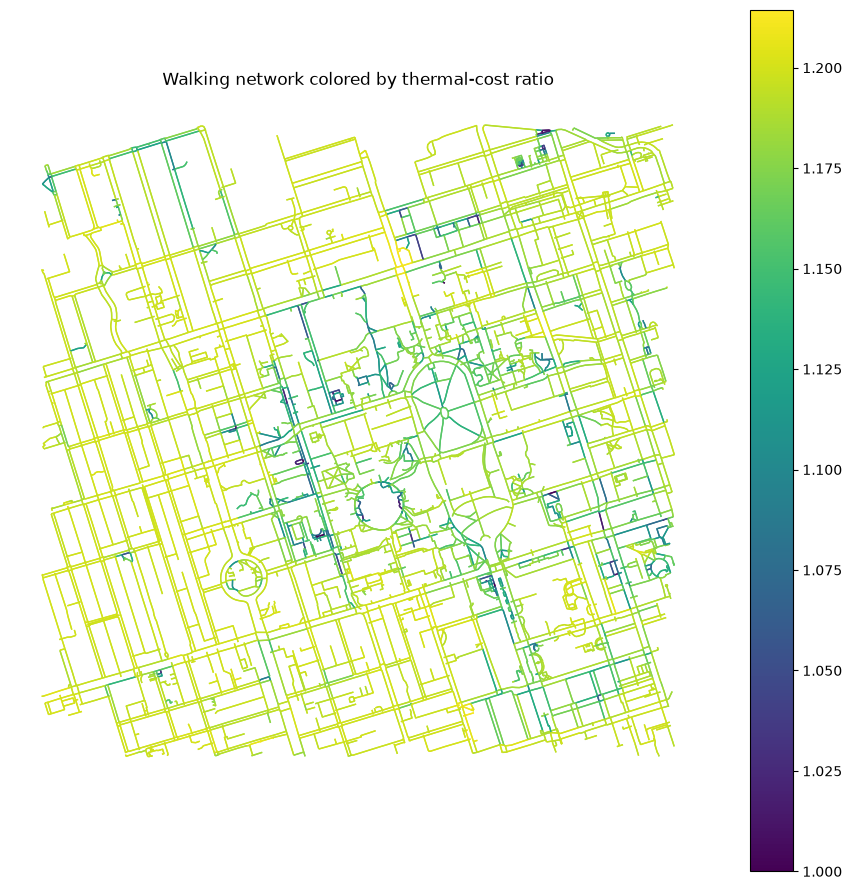

In [34]:
thermal_graph_path = existing_path(
    INTERIM
    / "thermal_network"
    / "toronto_uoft_walk_thermal.graphml",
)

if thermal_graph_path:
    G_thermal = convert_graph_numeric(
        ox.load_graphml(thermal_graph_path)
    )

    nodes_t, edges_t = ox.graph_to_gdfs(
        G_thermal,
        nodes=True,
        edges=True,
        fill_edge_geometry=True,
    )

    if "utci_1500" in edges_t.columns:
        edges_t["utci_1500"] = pd.to_numeric(
            edges_t["utci_1500"],
            errors="coerce",
        )

        fig, ax = plt.subplots(figsize=(9, 9))

        edges_t.plot(
            ax=ax,
            column="utci_1500",
            linewidth=1.0,
            legend=True,
        )

        ax.set_title("Walking network colored by edge UTCI")
        ax.set_axis_off()
        plt.tight_layout()
        savefig(fig, FIG["thermal_network_utci"])
        plt.show()

        log_asset(
            "06",
            "Thermal network — edge UTCI",
            FIG["thermal_network_utci"],
        )

    if "cost_ratio" in edges_t.columns:
        edges_t["cost_ratio"] = pd.to_numeric(
            edges_t["cost_ratio"],
            errors="coerce",
        )

        fig, ax = plt.subplots(figsize=(9, 9))

        edges_t.plot(
            ax=ax,
            column="cost_ratio",
            linewidth=1.0,
            legend=True,
        )

        ax.set_title(
            "Walking network colored by thermal-cost ratio"
        )
        ax.set_axis_off()
        plt.tight_layout()
        savefig(fig, FIG["thermal_network_cost"])
        plt.show()

        log_asset(
            "06",
            "Thermal network — cost ratio",
            FIG["thermal_network_cost"],
        )

    edges_t.reset_index().to_file(
        FINAL_LAYERS / "thermal_network_anchor_edges.gpkg",
        driver="GPKG",
    )

else:
    edges_t = None
    print("Thermal network GraphML not found.")
    log_asset("06", "Thermal network", None, "missing")

# Part II — Accessibility design and modeled loss

## 11. Accessibility origins and transit destinations

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_08_origins_and_transit_stops.png


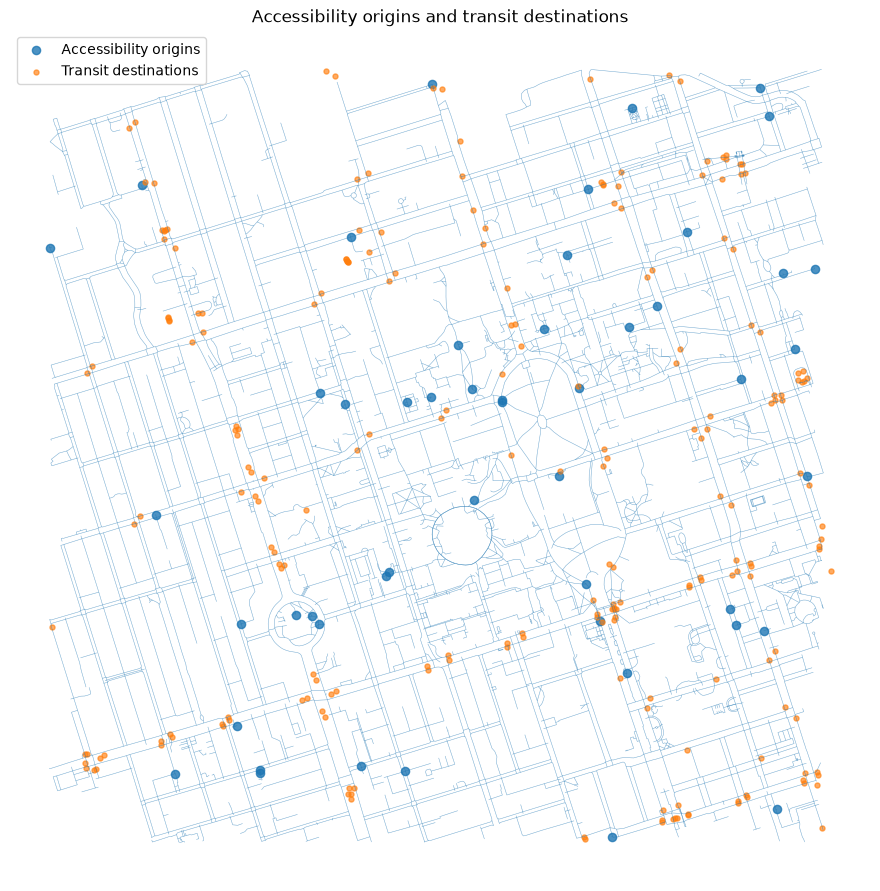

In [35]:
origins_path = existing_path(
    OUTPUTS
    / "accessibility"
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg",
)

transit_cache_path = existing_path(
    INTERIM
    / "accessibility"
    / "uoft_transit_stops.gpkg",
)

if origins_path:
    origins = gpd.read_file(origins_path)

    fig, ax = plt.subplots(figsize=(9, 9))

    if edges_t is not None:
        origins_plot = origins.to_crs(edges_t.crs)

        edges_t.plot(
            ax=ax,
            linewidth=0.35,
            alpha=0.35,
        )
    else:
        origins_plot = origins

    origins_plot.plot(
        ax=ax,
        markersize=35,
        alpha=0.8,
        label="Accessibility origins",
    )

    if transit_cache_path:
        transit = gpd.read_file(transit_cache_path)

        if transit.crs != origins_plot.crs:
            transit = transit.to_crs(origins_plot.crs)

        transit["geometry"] = transit.geometry.centroid

        transit.plot(
            ax=ax,
            markersize=13,
            alpha=0.65,
            label="Transit destinations",
        )

    ax.set_title(
        "Accessibility origins and transit destinations"
    )
    ax.legend()
    ax.set_axis_off()
    plt.tight_layout()
    savefig(fig, FIG["origins_transit"])
    plt.show()

    log_asset(
        "07",
        "Origins and transit destinations",
        FIG["origins_transit"],
    )

else:
    origins = None
    print("Origin accessibility GPKG not found.")
    log_asset(
        "07",
        "Origins and transit destinations",
        None,
        "missing",
    )

## 12. Accessibility loss map

**Accessibility loss** is the percentage reduction in reachable transit destinations after normal walking cost is replaced by heat-conditioned generalized cost.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_09_accessibility_loss_map.png


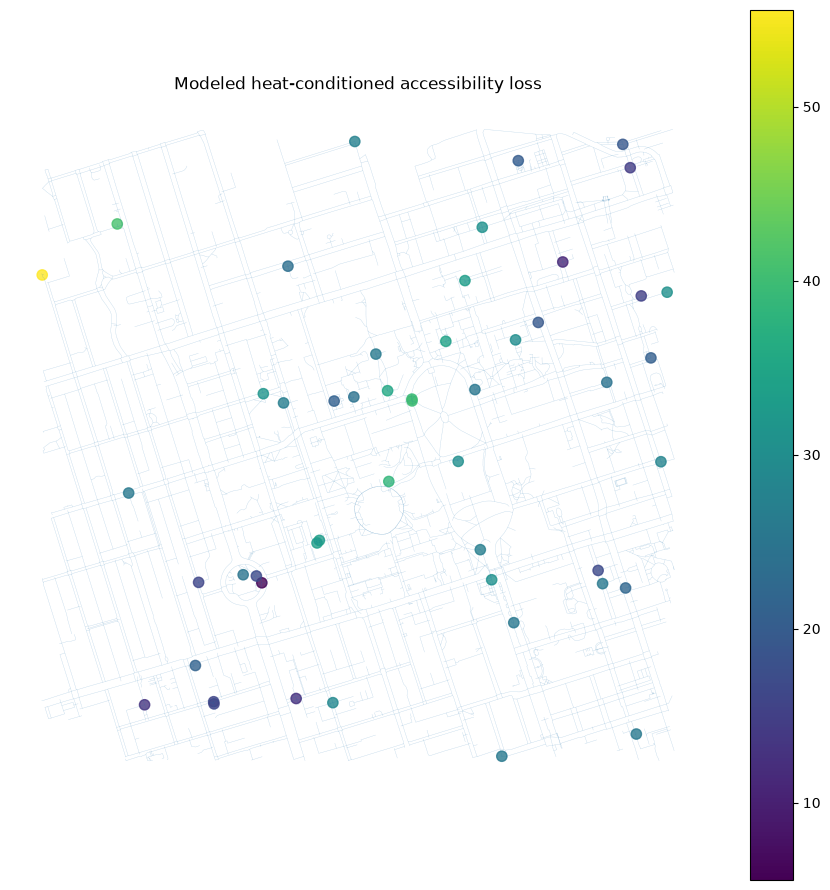

In [36]:
if origins is not None:
    candidate_cols = [
        "absolute_loss_pct",
        "accessibility_loss_pct",
        "loss_pct",
    ]

    loss_col = next(
        (
            c
            for c in candidate_cols
            if c in origins.columns
        ),
        None,
    )

    if loss_col:
        origins_plot = origins.copy()

        if edges_t is not None:
            origins_plot = origins_plot.to_crs(edges_t.crs)

        fig, ax = plt.subplots(figsize=(9, 9))

        if edges_t is not None:
            edges_t.plot(
                ax=ax,
                linewidth=0.25,
                alpha=0.15,
            )

        origins_plot.plot(
            ax=ax,
            column=loss_col,
            markersize=55,
            alpha=0.8,
            legend=True,
        )

        ax.set_title(
            "Modeled heat-conditioned accessibility loss"
        )
        ax.set_axis_off()
        plt.tight_layout()
        savefig(fig, FIG["access_loss_map"])
        plt.show()

        log_asset(
            "07",
            "Accessibility loss map",
            FIG["access_loss_map"],
        )

        origins.to_file(
            FINAL_LAYERS
            / "accessibility_origins_final.gpkg",
            driver="GPKG",
        )

    else:
        print("No accessibility-loss column found.")
        log_asset(
            "07",
            "Accessibility loss map",
            None,
            "missing",
        )

# Part III — Observed Bike Share response

## 13. Bike Share station-scenario response

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_10_bikeshare_response_distribution.png


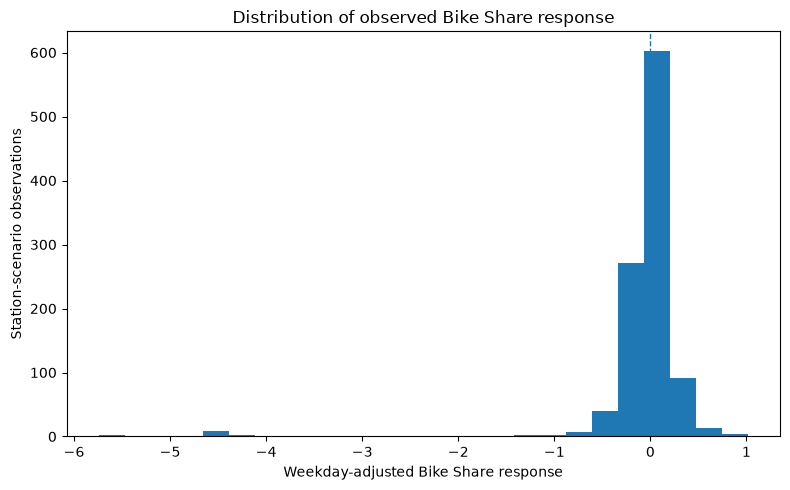

In [37]:
linked_path = existing_path(
    OUTPUTS
    / "multiscenario_accessibility_bikeshare"
    / "toronto_multiscenario_accessibility_bikeshare_station_panel.csv",
)

if linked_path:
    linked = pd.read_csv(linked_path)

    linked["date"] = pd.to_datetime(
        linked["date"]
    )

    if "weekday_adjusted_response" in linked.columns:
        fig, ax = plt.subplots(figsize=(8, 5))

        linked[
            "weekday_adjusted_response"
        ].dropna().plot.hist(
            ax=ax,
            bins=25,
        )

        ax.axvline(
            0,
            linewidth=1,
            linestyle="--",
        )

        ax.set_xlabel(
            "Weekday-adjusted Bike Share response"
        )
        ax.set_ylabel(
            "Station-scenario observations"
        )
        ax.set_title(
            "Distribution of observed Bike Share response"
        )
        plt.tight_layout()
        savefig(fig, FIG["bikeshare_response"])
        plt.show()

        log_asset(
            "08–10",
            "Bike Share response distribution",
            FIG["bikeshare_response"],
        )

else:
    linked = None
    print("Linked station-scenario panel not found.")

## 14. Accessibility loss × Bike Share response

A negative association means that stations with larger modeled thermal-accessibility losses tend to show weaker same-day Bike Share activity relative to their weekday expectation.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_11_accessibility_vs_bikeshare.png


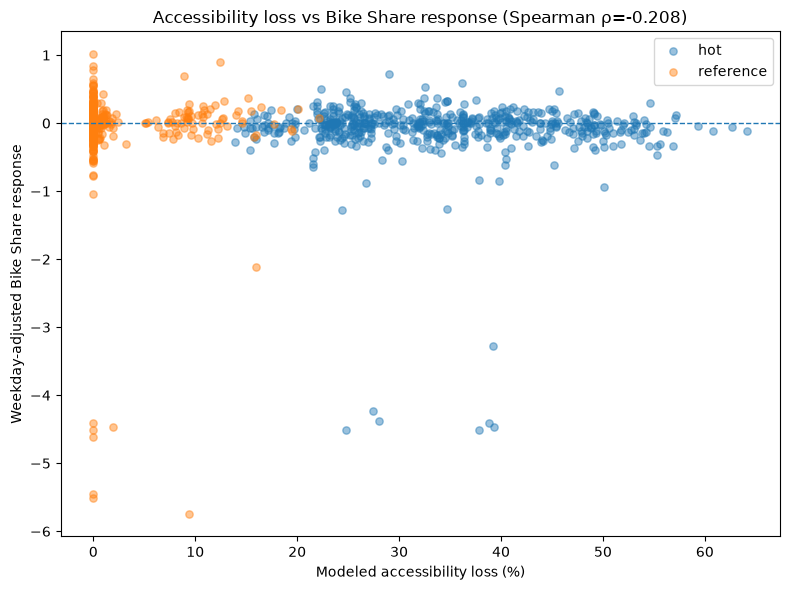

In [38]:
if linked is not None:
    required_cols = [
        "modeled_accessibility_loss_pct",
        "weekday_adjusted_response",
    ]

    if all(
        c in linked.columns
        for c in required_cols
    ):
        valid = linked[
            required_cols
        ].dropna()

        rho, p = spearmanr(
            valid[
                "modeled_accessibility_loss_pct"
            ],
            valid[
                "weekday_adjusted_response"
            ],
        )

        fig, ax = plt.subplots(figsize=(8, 6))

        if "scenario_role" in linked.columns:
            for role in linked[
                "scenario_role"
            ].dropna().unique():

                subset = linked[
                    linked[
                        "scenario_role"
                    ] == role
                ]

                ax.scatter(
                    subset[
                        "modeled_accessibility_loss_pct"
                    ],
                    subset[
                        "weekday_adjusted_response"
                    ],
                    s=28,
                    alpha=0.45,
                    label=role,
                )

            ax.legend()

        else:
            ax.scatter(
                linked[
                    "modeled_accessibility_loss_pct"
                ],
                linked[
                    "weekday_adjusted_response"
                ],
                s=28,
                alpha=0.45,
            )

        ax.axhline(
            0,
            linewidth=1,
            linestyle="--",
        )

        ax.set_xlabel(
            "Modeled accessibility loss (%)"
        )
        ax.set_ylabel(
            "Weekday-adjusted Bike Share response"
        )
        ax.set_title(
            f"Accessibility loss vs Bike Share response "
            f"(Spearman ρ={rho:.3f})"
        )

        plt.tight_layout()
        savefig(fig, FIG["access_bike_scatter"])
        plt.show()

        log_asset(
            "14",
            "Accessibility–Bike Share association",
            FIG["access_bike_scatter"],
        )

        primary_link_summary = pd.DataFrame(
            [
                {
                    "observations": len(valid),
                    "spearman_rho": rho,
                    "naive_p_value": p,
                }
            ]
        )

        primary_link_summary.to_csv(
            FINAL_TABLES
            / "tbl_05_primary_accessibility_bikeshare_link.csv",
            index=False,
        )

# Part IV — Multi-scenario results and robustness

## 15. Multi-scenario thermal impedance

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_12_multiscenario_thermal_impedance.png


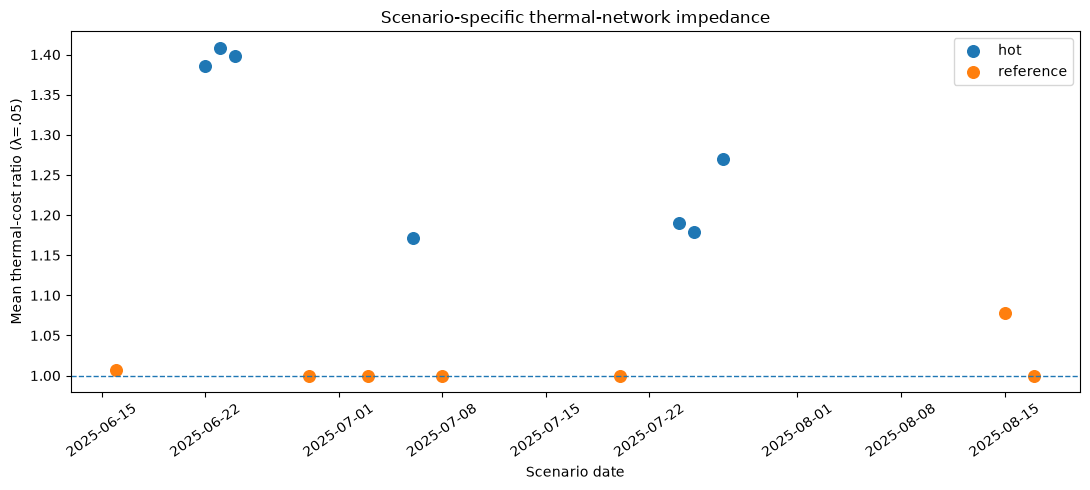

In [39]:
network_summary_path = existing_path(
    OUTPUTS
    / "thermal_network_multiday"
    / "toronto_multiday_thermal_network_summary.csv",
)

if network_summary_path:
    network_summary = pd.read_csv(
        network_summary_path
    )

    network_summary["date"] = pd.to_datetime(
        network_summary["date"]
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    for role in network_summary[
        "scenario_role"
    ].dropna().unique():

        subset = network_summary[
            network_summary[
                "scenario_role"
            ] == role
        ].sort_values("date")

        ax.scatter(
            subset["date"],
            subset[
                "mean_cost_ratio_lambda_005"
            ],
            s=70,
            label=role,
        )

    ax.axhline(
        1.0,
        linewidth=1,
        linestyle="--",
    )
    ax.set_xlabel("Scenario date")
    ax.set_ylabel(
        "Mean thermal-cost ratio (λ=.05)"
    )
    ax.set_title(
        "Scenario-specific thermal-network impedance"
    )
    ax.legend()
    plt.xticks(rotation=35)
    plt.tight_layout()
    savefig(fig, FIG["scenario_impedance"])
    plt.show()

    log_asset(
        "12–13",
        "Multi-scenario thermal impedance",
        FIG["scenario_impedance"],
    )

    network_summary.to_csv(
        FINAL_TABLES
        / "tbl_03_multiscenario_thermal_network.csv",
        index=False,
    )

else:
    network_summary = None
    print("Multi-scenario network summary not found.")

## 16. Multi-scenario accessibility loss

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_13_multiscenario_accessibility_loss.png


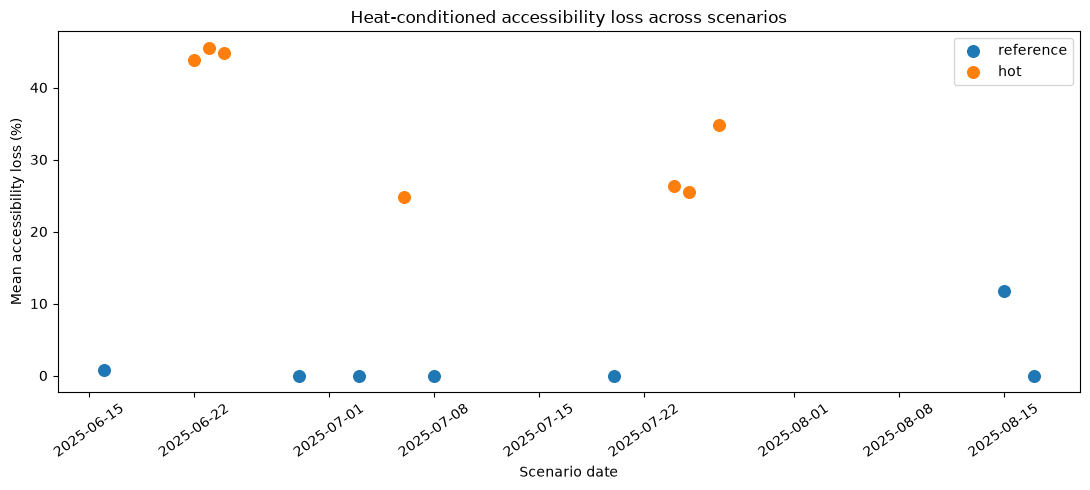

In [40]:
access_summary_path = existing_path(
    OUTPUTS
    / "multiscenario_accessibility_bikeshare"
    / "toronto_multiscenario_accessibility_summary.csv",
)

if access_summary_path:
    access_summary = pd.read_csv(
        access_summary_path
    )

    access_summary["date"] = pd.to_datetime(
        access_summary["date"]
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    for role in access_summary[
        "scenario_role"
    ].dropna().unique():

        subset = access_summary[
            access_summary[
                "scenario_role"
            ] == role
        ].sort_values("date")

        ax.scatter(
            subset["date"],
            subset[
                "mean_accessibility_loss_pct"
            ],
            s=70,
            label=role,
        )

    ax.set_xlabel("Scenario date")
    ax.set_ylabel(
        "Mean accessibility loss (%)"
    )
    ax.set_title(
        "Heat-conditioned accessibility loss across scenarios"
    )
    ax.legend()
    plt.xticks(rotation=35)
    plt.tight_layout()
    savefig(fig, FIG["scenario_access_loss"])
    plt.show()

    log_asset(
        "14",
        "Multi-scenario accessibility loss",
        FIG["scenario_access_loss"],
    )

    access_summary.to_csv(
        FINAL_TABLES
        / "tbl_04_multiscenario_accessibility.csv",
        index=False,
    )

else:
    access_summary = None
    print("Multi-scenario accessibility summary not found.")

## 17. Robustness: 75 vs 50 stations

The 50-station core is a predefined spatial sensitivity check, not an outcome-selected sample.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_14_robustness_50_vs_75.png


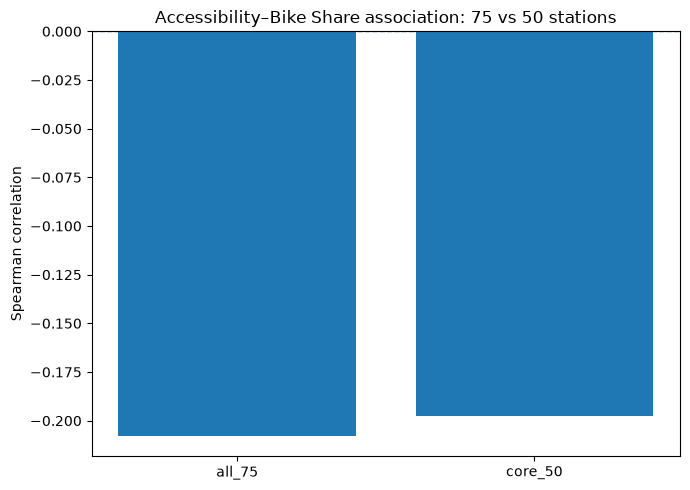

In [41]:
sample_compare_path = existing_path(
    OUTPUTS
    / "robustness"
    / "station_sample_75_vs_50.csv",
)

robustness_path = existing_path(
    OUTPUTS
    / "robustness"
    / "lambda_threshold_robustness.csv",
)

if sample_compare_path:
    sample_compare = pd.read_csv(
        sample_compare_path
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.bar(
        sample_compare["sample"],
        sample_compare["spearman_rho"],
    )

    ax.axhline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_ylabel("Spearman correlation")
    ax.set_title(
        "Accessibility–Bike Share association: 75 vs 50 stations"
    )

    plt.tight_layout()
    savefig(fig, FIG["sample_robustness"])
    plt.show()

    log_asset(
        "15",
        "75 vs 50 station robustness",
        FIG["sample_robustness"],
    )

    sample_compare.to_csv(
        FINAL_TABLES
        / "tbl_06_station_sample_robustness.csv",
        index=False,
    )

else:
    sample_compare = None
    print("75-vs-50 station table not found.")

## 18. λ and threshold sensitivity

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_15_lambda_sensitivity.png


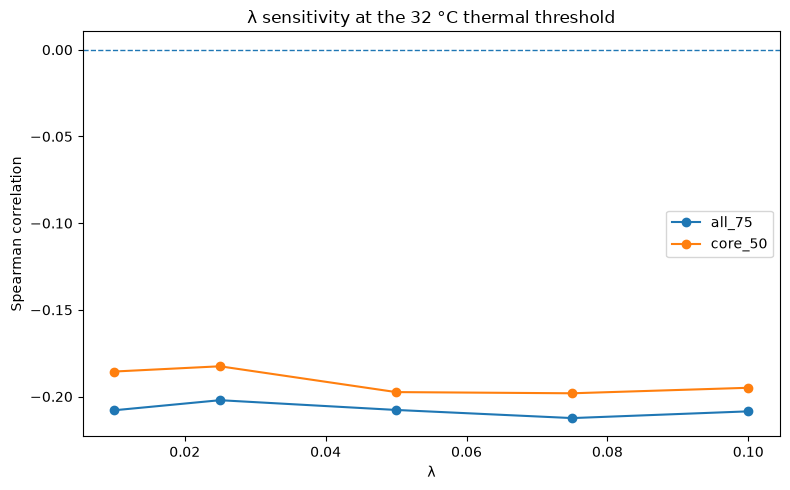

In [42]:
if robustness_path:
    robustness = pd.read_csv(
        robustness_path
    )

    plot_df = robustness[
        robustness[
            "threshold_C"
        ] == 32.0
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 5))

    for sample_name in plot_df[
        "sample"
    ].dropna().unique():

        subset = plot_df[
            plot_df[
                "sample"
            ] == sample_name
        ].sort_values("lambda")

        ax.plot(
            subset["lambda"],
            subset["spearman_rho"],
            marker="o",
            label=sample_name,
        )

    ax.axhline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_xlabel("λ")
    ax.set_ylabel("Spearman correlation")
    ax.set_title(
        "λ sensitivity at the 32 °C thermal threshold"
    )
    ax.legend()

    plt.tight_layout()
    savefig(fig, FIG["lambda_sensitivity"])
    plt.show()

    log_asset(
        "15",
        "Lambda sensitivity",
        FIG["lambda_sensitivity"],
    )

    robustness.to_csv(
        FINAL_TABLES
        / "tbl_07_lambda_threshold_robustness.csv",
        index=False,
    )

else:
    robustness = None
    print("Lambda/threshold robustness table not found.")

# Part V — Terminology and Quarto handoff

## 19. Final terminology glossary

In [43]:
glossary = pd.DataFrame(
    [
        {
            "term": "Thermal scenario",
            "definition": "A specific modeled summer weather condition used to generate a SOLWEIG thermal field and downstream network effects.",
        },
        {
            "term": "UTCI",
            "definition": "Universal Thermal Climate Index, used here as the main outdoor thermal-stress indicator.",
        },
        {
            "term": "Edge UTCI",
            "definition": "The mean UTCI sampled along an individual walking-network edge.",
        },
        {
            "term": "Thermal threshold",
            "definition": "The UTCI value above which additional thermal penalty begins. The reference model uses 32 °C.",
        },
        {
            "term": "Heat excess",
            "definition": "The amount by which edge-level UTCI exceeds the selected thermal threshold.",
        },
        {
            "term": "Lambda (λ)",
            "definition": "The sensitivity parameter controlling how strongly heat excess inflates generalized walking cost. It is not behaviorally calibrated in the current PoC.",
        },
        {
            "term": "Thermal generalized cost",
            "definition": "Normal walking time after applying the thermal penalty. It is a generalized cost rather than literal perceived time.",
        },
        {
            "term": "Thermal-cost ratio",
            "definition": "Heat-conditioned generalized edge cost divided by normal walking time.",
        },
        {
            "term": "Normal accessibility",
            "definition": "The number of transit destinations reachable within the 600-second budget using ordinary walking time.",
        },
        {
            "term": "Heat-conditioned accessibility",
            "definition": "The number of transit destinations reachable within the same budget using thermal generalized cost.",
        },
        {
            "term": "Accessibility loss",
            "definition": "The percentage reduction in reachable destinations when normal walking cost is replaced by heat-conditioned cost.",
        },
        {
            "term": "Hot scenario",
            "definition": "A selected high-temperature summer scenario representing stronger thermal stress.",
        },
        {
            "term": "Reference scenario",
            "definition": "A moderate comparison scenario paired with a hot scenario.",
        },
        {
            "term": "Anchor scenario",
            "definition": "The July 25, 2025 event retained to connect the original single-event PoC with the multi-scenario workflow.",
        },
        {
            "term": "Weekday-adjusted Bike Share response",
            "definition": "Observed station-day Bike Share activity relative to that station's expected activity for the same weekday.",
        },
        {
            "term": "Core 50-station sample",
            "definition": "A predefined spatial robustness subset of the full 75-station sample.",
        },
        {
            "term": "Observational behavioral support",
            "definition": "Evidence that modeled accessibility variation aligns systematically with observed mobility variation, without implying causal validation.",
        },
        {
            "term": "Behavioral validation",
            "definition": "A stronger claim requiring evidence that the model accurately reproduces actual traveler behavior; not established by the current PoC.",
        },
        {
            "term": "Network saturation",
            "definition": "A condition in which nearly all network edges exceed the thermal threshold, making the penalty closer to a uniform network inflation.",
        },
        {
            "term": "Robustness analysis",
            "definition": "Testing whether findings persist under alternative station samples, lambda values, or UTCI thresholds.",
        },
    ]
)

glossary.to_csv(
    FINAL_TABLES
    / "tbl_01_terminology_glossary.csv",
    index=False,
)

display(glossary)

,term,definition
0,Thermal scenario,A specific modeled summer weather condition us...
1,UTCI,"Universal Thermal Climate Index, used here as ..."
2,Edge UTCI,The mean UTCI sampled along an individual walk...
3,Thermal threshold,The UTCI value above which additional thermal ...
4,Heat excess,The amount by which edge-level UTCI exceeds th...
5,Lambda (λ),The sensitivity parameter controlling how stro...
6,Thermal generalized cost,Normal walking time after applying the thermal...
7,Thermal-cost ratio,Heat-conditioned generalized edge cost divided...
8,Normal accessibility,The number of transit destinations reachable w...
9,Heat-conditioned accessibility,The number of transit destinations reachable w...


## 20. Workflow stage summary

In [44]:
workflow_steps = pd.DataFrame(
    [
        ["01", "Study area", "Define Toronto / U of T spatial domain and walking network."],
        ["02–03", "Urban form", "Prepare buildings, heights, trees, and vegetation inputs."],
        ["04", "SOLWEIG inputs", "Prepare aligned DEM, DSM, and CDSM rasters."],
        ["05", "Thermal field", "Run SOLWEIG and produce UTCI/Tmrt thermal surfaces."],
        ["06", "Thermal network", "Transfer UTCI to walking edges and calculate thermal cost."],
        ["07", "Accessibility", "Compare normal and heat-conditioned reachable transit destinations."],
        ["08–10", "Bike Share", "Prepare observed station-day mobility response."],
        ["11–14", "Multi-scenario extension", "Run multiple thermal scenarios and recompute network/accessibility."],
        ["15", "Robustness", "Test 75 vs 50 stations, lambda sensitivity, and threshold sensitivity."],
        ["16", "Final synthesis", "Export final figures, tables, glossary, and Quarto-ready assets."],
    ],
    columns=[
        "stage",
        "title",
        "description",
    ],
)

workflow_steps.to_csv(
    FINAL_TABLES / "tbl_00_workflow_steps.csv",
    index=False,
)

display(workflow_steps)

,stage,title,description
0,01,Study area,Define Toronto / U of T spatial domain and wal...
1,02–03,Urban form,"Prepare buildings, heights, trees, and vegetat..."
2,04,SOLWEIG inputs,"Prepare aligned DEM, DSM, and CDSM rasters."
3,05,Thermal field,Run SOLWEIG and produce UTCI/Tmrt thermal surf...
4,06,Thermal network,Transfer UTCI to walking edges and calculate t...
5,07,Accessibility,Compare normal and heat-conditioned reachable ...
6,08–10,Bike Share,Prepare observed station-day mobility response.
7,11–14,Multi-scenario extension,Run multiple thermal scenarios and recompute n...
8,15,Robustness,"Test 75 vs 50 stations, lambda sensitivity, an..."
9,16,Final synthesis,"Export final figures, tables, glossary, and Qu..."


## 21. Final workflow gallery

This creates one visual storyboard of the Toronto proof-of-concept.

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/final_figures/fig_16_workflow_gallery.png


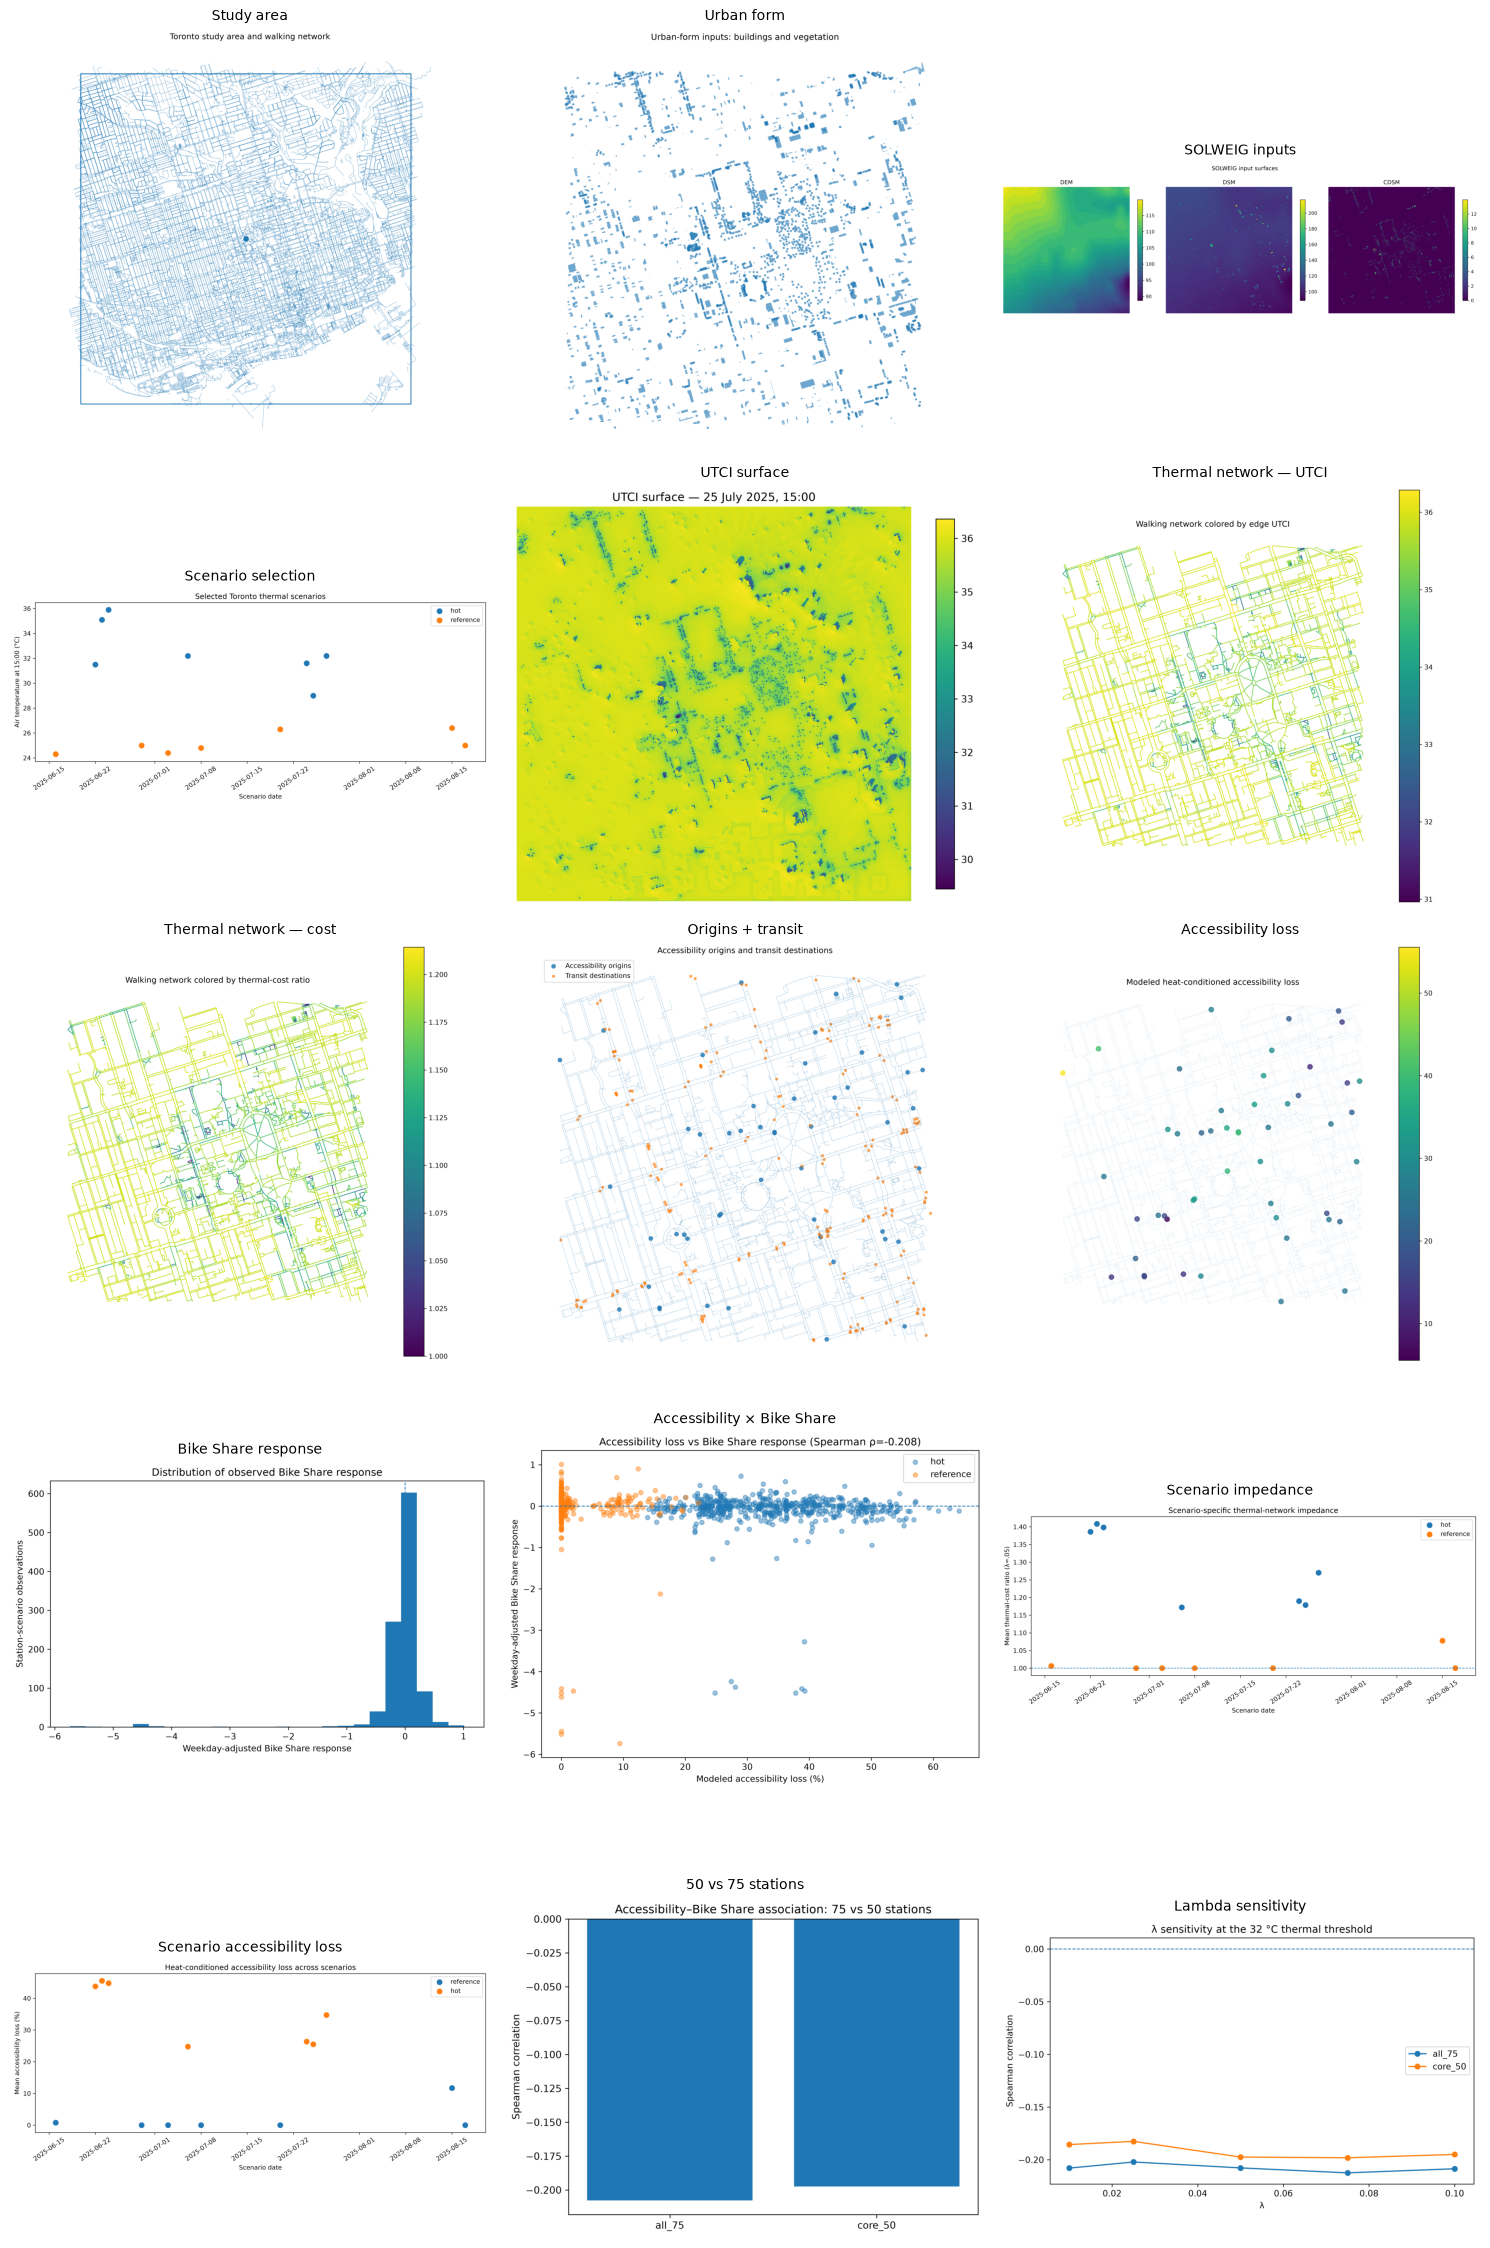

In [45]:
gallery_items = []

gallery_order = [
    ("Study area", FIG["study_area"]),
    ("Urban form", FIG["urban_form"]),
    ("SOLWEIG inputs", FIG["surface_inputs"]),
    ("Scenario selection", FIG["scenario_selection"]),
    ("UTCI surface", FIG["utci_anchor"]),
    ("Thermal network — UTCI", FIG["thermal_network_utci"]),
    ("Thermal network — cost", FIG["thermal_network_cost"]),
    ("Origins + transit", FIG["origins_transit"]),
    ("Accessibility loss", FIG["access_loss_map"]),
    ("Bike Share response", FIG["bikeshare_response"]),
    ("Accessibility × Bike Share", FIG["access_bike_scatter"]),
    ("Scenario impedance", FIG["scenario_impedance"]),
    ("Scenario accessibility loss", FIG["scenario_access_loss"]),
    ("50 vs 75 stations", FIG["sample_robustness"]),
    ("Lambda sensitivity", FIG["lambda_sensitivity"]),
]

for label, path in gallery_order:
    if path.exists():
        gallery_items.append(
            (label, path)
        )

if gallery_items:
    n = len(gallery_items)
    ncols = 3
    nrows = int(
        np.ceil(n / ncols)
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4.6 * nrows),
    )

    axes = np.atleast_1d(
        axes
    ).ravel()

    for ax in axes[n:]:
        ax.axis("off")

    for ax, (
        label,
        path,
    ) in zip(
        axes,
        gallery_items,
    ):
        img = mpimg.imread(path)
        ax.imshow(img)
        ax.set_title(
            label,
            fontsize=10,
        )
        ax.axis("off")

    plt.tight_layout()
    savefig(
        fig,
        FIG["workflow_gallery"],
    )
    plt.show()

    log_asset(
        "16",
        "Workflow gallery",
        FIG["workflow_gallery"],
    )

else:
    print("No figures available for gallery.")

## 22. Copy final assets into the Quarto handoff folder

In [46]:
for path in FINAL_FIGURES.glob("*.png"):
    shutil.copy2(
        path,
        QUARTO_FIGURES / path.name,
    )

for path in FINAL_TABLES.glob("*.csv"):
    shutil.copy2(
        path,
        QUARTO_TABLES / path.name,
    )

print(
    "Copied final figures to:",
    QUARTO_FIGURES,
)
print(
    "Copied final tables to:",
    QUARTO_TABLES,
)

Copied final figures to: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/quarto_assets/figures
Copied final tables to: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/processed/quarto_assets/tables


## 23. Quarto-ready narrative snippets

In [47]:
workflow_text = (
    "Toronto heat-conditioned accessibility workflow\n\n"
    "Urban form + meteorology -> UTCI -> thermal network impedance -> "
    "heat-conditioned accessibility -> observed mobility response\n\n"
    "The Toronto proof-of-concept combines detailed urban-form inputs, "
    "SOLWEIG thermal modeling, a walking network, transit accessibility, "
    "and Bike Share activity. The same network topology is retained across "
    "thermal scenarios while edge costs vary with UTCI."
)

interpretation_text = (
    "Accessibility loss is a modeled percentage reduction in reachable "
    "destinations, not an observed trip loss.\n\n"
    "Lambda (λ) is a thermal-impedance sensitivity parameter, not a calibrated "
    "behavioral coefficient.\n\n"
    "Bike Share is used as observational behavioral support rather than full "
    "behavioral validation.\n\n"
    "The strongest result is the stability of the negative accessibility–mobility "
    "association across the full 75-station sample, the predefined 50-station "
    "core, five λ values, and three UTCI thresholds."
)

(
    QUARTO_TEXT
    / "workflow_summary.txt"
).write_text(
    workflow_text,
    encoding="utf-8",
)

(
    QUARTO_TEXT
    / "interpretation_notes.txt"
).write_text(
    interpretation_text,
    encoding="utf-8",
)

print("Saved Quarto narrative snippets.")

Saved Quarto narrative snippets.


## 24. Final asset inventory

In [48]:
asset_log_df = pd.DataFrame(
    asset_log
)

asset_log_df.to_csv(
    FINAL_TABLES
    / "tbl_98_figure_generation_log.csv",
    index=False,
)

inventory_rows = []

for base_name, base_dir in [
    ("final_figures", FINAL_FIGURES),
    ("final_tables", FINAL_TABLES),
    ("final_layers", FINAL_LAYERS),
    ("quarto_assets", QUARTO_ASSETS),
]:
    for path in sorted(
        base_dir.rglob("*")
    ):
        if path.is_file():
            inventory_rows.append(
                {
                    "group": base_name,
                    "relative_path": str(
                        path.relative_to(
                            PROJECT_ROOT
                        )
                    ),
                    "size_kb": round(
                        path.stat().st_size
                        / 1024,
                        1,
                    ),
                }
            )

inventory = pd.DataFrame(
    inventory_rows
)

inventory.to_csv(
    FINAL_TABLES
    / "tbl_99_asset_inventory.csv",
    index=False,
)

display(asset_log_df)
display(inventory)

print()
print(
    "Final figures:",
    len(
        list(
            FINAL_FIGURES.glob(
                "*.png"
            )
        )
    ),
)
print(
    "Final tables:",
    len(
        list(
            FINAL_TABLES.glob(
                "*.csv"
            )
        )
    ),
)
print(
    "Final layers:",
    len(
        list(
            FINAL_LAYERS.glob(
                "*"
            )
        )
    ),
)

,stage,label,path,status
0,01,Study area and walking network,/scratch/project_2010417/paper3/heat-condition...,created
1,02–03,Buildings and vegetation,/scratch/project_2010417/paper3/heat-condition...,created
2,04,SOLWEIG input surfaces,/scratch/project_2010417/paper3/heat-condition...,created
3,11,Thermal scenario selection,/scratch/project_2010417/paper3/heat-condition...,created
4,05,Anchor UTCI surface,/scratch/project_2010417/paper3/heat-condition...,created
5,06,Thermal network — edge UTCI,/scratch/project_2010417/paper3/heat-condition...,created
6,06,Thermal network — cost ratio,/scratch/project_2010417/paper3/heat-condition...,created
7,07,Origins and transit destinations,/scratch/project_2010417/paper3/heat-condition...,created
8,07,Accessibility loss map,/scratch/project_2010417/paper3/heat-condition...,created
9,08–10,Bike Share response distribution,/scratch/project_2010417/paper3/heat-condition...,created


,group,relative_path,size_kb
0,final_figures,data/toronto/processed/final_figures/fig_01_st...,4080.3
1,final_figures,data/toronto/processed/final_figures/fig_02_bu...,800.8
2,final_figures,data/toronto/processed/final_figures/fig_03_so...,615.6
3,final_figures,data/toronto/processed/final_figures/fig_04_th...,159.7
4,final_figures,data/toronto/processed/final_figures/fig_05_an...,407.6
5,final_figures,data/toronto/processed/final_figures/fig_06_th...,1810.1
6,final_figures,data/toronto/processed/final_figures/fig_07_th...,1856.6
7,final_figures,data/toronto/processed/final_figures/fig_08_or...,1772.2
8,final_figures,data/toronto/processed/final_figures/fig_09_ac...,976.8
9,final_figures,data/toronto/processed/final_figures/fig_10_bi...,88.2



Final figures: 16
Final tables: 10
Final layers: 2


# Final interpretation

The Toronto workflow now provides a complete visual and analytical chain:

**study area → urban form → thermal field → thermal network → accessibility loss → Bike Share response → robustness**

The Quarto site should use the exported assets in:

`data/toronto/processed/quarto_assets/`

The main scientific interpretation remains cautious:

- thermal conditions materially alter generalized walking impedance;
- heat-conditioned accessibility is scenario dependent;
- greater modeled accessibility loss is associated with weaker same-day Bike Share activity;
- the association is modest but consistently negative across reasonable model specifications;
- the current results provide **observational behavioral support**, not causal validation or calibration of λ.